# 01 · Preprocessing — Wu 2021 Breast Carcinoma (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed,
remove detached islands, and split the manifold into its transcriptional compartments.
Breast malignant cells are strongly **patient-specific** (CNV-driven), so batch
integration is the crux of Gate 1 here. Every tunable choice is *derived from this
dataset*, not inherited from the head-and-neck reference. Deliverable: `processed.h5ad`,
`samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
CITE = 'Wu et al., 2021'
print('dataset:', name, '| category:', cat)

dataset: Wu2021_Breast | category: Breast


### Load malignant compartment
Wu et al. annotate cell type directly; we take their `Malignant` calls. Object-dtype obs
columns are coerced to string so the AnnData serialises cleanly (clinical metadata carries
mixed types).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
for c in adata.obs.columns:
    if adata.obs[c].dtype == object: adata.obs[c] = adata.obs[c].astype(str)
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Wu2021_Breast
Done.
full atlas: (100064, 29733)
malignant: (24489, 29733) | samples: 20
expression: X max 7.98 (log1p of normalize_total counts)


### Sample thresholding — multiplicative-gap rule, with its premise tested
The head-and-neck / colorectal references cut thin samples at the largest **multiplicative
cliff** in the sorted per-sample counts. That rule presumes a genuine lower-tail
separatrix. Here the premise **fails**: Wu 2021's counts decline smoothly (4053 -> 124) with
no cliff, and the largest multiplicative jump lands at the **top** rank (4018 -> 2352), which
is nonsensical as a lower cut. We detect this (gap not in the lower half) and fall back to
the protocol's **min-cell floor** (100), keeping all samples — the honest choice when the
gap rule is ill-defined.

In [4]:
n = adata.obs['sample'].value_counts(); vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]; gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values.astype(int))
print(f'largest multiplicative gap: rank {gap}, {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
lower_half = gap >= len(vals)//2
print('gap sits in lower half (valid lower-tail separatrix)?', lower_half)
if lower_half and ratios[gap] >= 1.5:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1])); rule = f'multiplicative gap (geo-mean = {thresh})'
else:
    thresh = 100; rule = 'min-cell floor = 100 (gap rule ill-defined: smooth counts, largest cliff at top rank)'
print(f'-> threshold = {thresh} via {rule}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [4053 4018 2352 2223 2169 1715 1184 1167 1058  894  813  659  521  441
  261  222  212  207  196  124]
largest multiplicative gap: rank 1, 4018 -> 2352 (ratio 1.71)
gap sits in lower half (valid lower-tail separatrix)? False
-> threshold = 100 via min-cell floor = 100 (gap rule ill-defined: smooth counts, largest cliff at top rank)
kept 20/20 samples -> 24489 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is chosen by a joint sweep: same-sample-neighbour fraction (lower = better mixing)
**and** the per-neighbourhood **iLISI** (median effective #samples; higher = better mixing),
the Gate-1 integration metric. Pre-Harmony each cell's neighbourhood is essentially a single
patient (iLISI ~ 1.0) — the expected CNV-driven patient specificity of breast malignant
cells. We take the theta at which mixing plateaus without over-correction; PCs stay in the
robust 20-dim range.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
codes = pd.Categorical(adata.obs['sample']).codes; nb = len(np.unique(codes))
def _ilisi(rep, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep); d, idx = nn.kneighbors(rep); d = d[:,1:]; idx = idx[:,1:]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        di = d[i]; w = np.exp(-(di**2)/(2*(di.mean()**2)+1e-12)); w /= w.sum()
        lab = codes[idx[i]]; p = np.array([w[lab==b].sum() for b in range(nb)]); out[i] = 1.0/np.sum(p**2)
    return float(np.median(out))

base = _same_sample_frac(adata.obsm['X_pca'][:,:20]); il_pre = _ilisi(adata.obsm['X_pca'][:,:20])
sweep = {}; ilsw = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=40, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20]); ilsw[th] = _ilisi(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample nbr frac | pre %.3f'%base, {k:round(v,3) for k,v in sweep.items()})
print('iLISI (median eff #samples, max=%d) | pre %.2f'%(nb, il_pre), {k:round(v,2) for k,v in ilsw.items()})
theta = 10
print(f'selected theta = {theta} (mixing plateaus; iLISI peaks {ilsw[theta]:.2f} vs pre {il_pre:.2f})')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=40, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2272 over-dispersed features (0:00:07) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2272
2026-07-31 03:48:26,693 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-31 03:48:31,158 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-31 03:48:31,371 - harmonypy - INFO - Iteration 1 of 40
2026-07-31 03:48:41,463 - harmonypy - INFO - Iteration 2 of 40
2026-07-31 03:48:51,529 - harmonypy - INFO - Iteration 3 of 40
2026-07-31 03:49:01,658 - harmonypy - INFO - Iteration 4 of 40
2026-07-31 03:49:11,829 - harmonypy - INFO - Iteration 5 of 40
2026-07-31 03:49:21,836 - harmonypy - INFO - Iteration 6 of 40
2026-07-31 03:49:31,986 - harmonypy - INFO - Iteration 7 of 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous manifold.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
nc,_ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN-graph connected components:', nc, '(1 = continuous)')

removed 0 cells in 0 detached islands
kNN-graph connected components: 1 (1 = continuous)


### Compartment split + labelling (data + publication)
Low-resolution Leiden (res=0.15) recovers two lobes. We label them *by biology*: the
compartment with the **lower cycling fraction** is the low-cycling candidate, the other
Cycling/Metabolic. `cell_cycle_phase` comes from the publication's phase calls; we also
cross-reference Wu et al.'s reported malignant subtypes (`cell_subtype`), satisfying the
requirement that annotation use both data-derived and publication calls.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
lab_map = {l: ('Low-cycling' if l==emb_lobe else 'Cycling/Metabolic')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
print('compartments:', adata.obs['compartment'].value_counts().to_dict())
print()
print('publication cell_subtype (data cross-reference):')
print(adata.obs['cell_subtype'].value_counts().head(6).to_string())
ct = pd.crosstab(adata.obs['compartment'], adata.obs['cell_subtype'])
ct = ct.div(ct.sum(1), axis=0)
print()
print('compartment x publication subtype (row-normalised, top 3):')
for cl in ct.index:
    top = ct.loc[cl].sort_values(ascending=False).head(3)
    print(f'  {cl}:', {k: round(v,2) for k,v in top.items()})

lobe sizes: {'1': 12686, '0': 11803}
cycling fraction per lobe: {'0': 0.07, '1': 0.22}
compartments: {'Cycling/Metabolic': 12686, 'Low-cycling': 11803}

publication cell_subtype (data cross-reference):
cell_subtype
Cancer LumA SC     7742
Cancer Cycling     5359
Cancer Basal SC    4312
Cancer Her2 SC     3708
Cancer LumB SC     3368

compartment x publication subtype (row-normalised, top 3):
  Low-cycling: {'Cancer LumA SC': 0.36, 'Cancer Basal SC': 0.2, 'Cancer Her2 SC': 0.18}
  Cycling/Metabolic: {'Cancer Cycling': 0.32, 'Cancer LumA SC': 0.27, 'Cancer Basal SC': 0.15}


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made
on the regenerated embedding itself (below) plus the iLISI gain (1.0 -> ~5) and the single
connected component. **Gate 1 = GO.**

In [8]:
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold (iLISI {il_pre:.2f} -> {ilsw[theta]:.2f}).')
print('radius-graph detached islands removed above; one connected kNN component retained.')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

20 samples share one continuous manifold (iLISI 1.00 -> 4.97).
radius-graph detached islands removed above; one connected kNN component retained.
Gate 1: samples intermixed on one continuous manifold -> GO


### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (24489, 25314)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, colour = sample. Intermixing across the
strip is the Gate-1 batch-integration evidence. Marker size is scaled to 15 (vs the ~30 used
for the ~11k-cell references) to hold equivalent visual density at 24k cells — a rendering
necessity, not a style change.

saved samples.pdf | cells: 24489


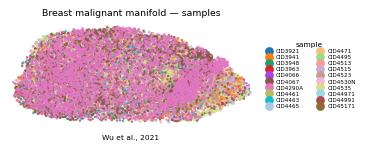

In [10]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=15, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.2, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, CITE, ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])